# Pemetaan Genangan Banjir Pasca-Siklon Senyar dari Citra Sentinel-1

Notebook pra-tubes Pengolahan Citra Digital. Studi kasus banjir akhir November 2025 di Kabupaten Aceh Utara dan Kota Lhokseumawe, fokus ke tahap preprocessing citra SAR sampai peta genangan awal.

| | |
| --- | --- |
| nama | Fathin Y |
| NIM | 241524041 |
| kelas | 3B |
| mata kuliah | Pengolahan Citra Digital, semester 5 |

Semua data dibaca dari katalog STAC Microsoft Planetary Computer tanpa Google Earth Engine:

| data | koleksi | dipakai untuk |
| --- | --- | --- |
| Sentinel-1 RTC (VV, VH) | `sentinel-1-rtc` | citra utama sebelum dan saat banjir |
| Sentinel-2 L2A | `sentinel-2-l2a` | validasi dengan MNDWI, 29 November 2025 |
| ESA WorldCover 2021 | `esa-worldcover` | mask air permanen dan luas terdampak per tutupan lahan |
| Copernicus DEM GLO-30 | `cop-dem-glo-30` | mask lereng curam |

Cara menjalankan: di Colab cukup Run all, sel pertama memasang paket yang belum ada. di lokal, dari root repo jalankan `uv sync` lalu buka notebook ini dengan kernel `.venv`. Hasil unduhan disimpan di `../data/` sebagai cache jadi run kedua tidak mengunduh ulang, dan gambar disimpan ke `../gambar/`

Catatan akses: halaman koleksi `sentinel-1-rtc` menyebut akun Planetary Computer diperlukan untuk SAS token, tapi saat notebook ini diuji (22 Oktober 2026) data terbaca tanpa akun. kalau nanti muncul error 403, daftar akun gratis di Planetary Computer lalu isi environment variable `PC_SDK_SUBSCRIPTION_KEY`

In [1]:
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install -q pystac-client planetary-computer odc-stac")

In [2]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import planetary_computer
import pystac_client
from matplotlib.colors import ListedColormap
from odc.stac import load
from skimage.filters import threshold_otsu

BASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA = BASE / "data"
GAMBAR = BASE / "gambar"
DATA.mkdir(exist_ok=True)
GAMBAR.mkdir(exist_ok=True)

# Kotak studi: Lhokseumawe sampai Panton Labu (lon, lat)
BBOX = [96.95, 4.85, 97.55, 5.25]
CRS = "EPSG:32647"  # UTM zona 47N
RES = 20            # meter, 10 m dirata rata 2x2 saat dibaca
PX_HA = RES * RES / 10_000

# Pasangan scene per orbit relatif: (sebelum, saat banjir). orbit sama = geometri pengamatan sama
PASANGAN = {
    41: ("2025-11-15", "2025-11-27"),   # Sentinel-1A, ascending
    143: ("2025-11-16", "2025-11-28"),  # Sentinel-1C, ascending
}
S2_TANGGAL = "2025-11-29"

KELAS = {10: "pohon", 20: "semak", 30: "rumput", 40: "lahan pertanian", 50: "terbangun",
         60: "lahan terbuka", 80: "air permanen", 90: "lahan basah", 95: "mangrove"}

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

## 1. Pencarian Scene

Satu tanggal di satu orbit biasanya terdiri dari dua sampai tiga scene yang bersambung sepanjang jalur satelit, jadi pencarian dikelompokkan per tanggal dan orbit. kolom `cakupan` menghitung berapa persen kotak studi yang tertutup scene tersebut

In [3]:
from shapely.geometry import box, shape
from shapely.ops import unary_union

aoi = box(*BBOX)
for orbit, tanggal in PASANGAN.items():
    for t in tanggal:
        items = list(catalog.search(collections=["sentinel-1-rtc"], bbox=BBOX, datetime=t,
                                    query={"sat:relative_orbit": {"eq": orbit}}).items())
        cakupan = unary_union([shape(i.geometry) for i in items]).intersection(aoi).area / aoi.area
        print(f"orbit {orbit:>3} | {t} | {len(items)} scene | cakupan {cakupan:.0%} | {items[0].id[:3]}")

orbit  41 | 2025-11-15 | 2 scene | cakupan 68% | S1A


orbit  41 | 2025-11-27 | 2 scene | cakupan 68% | S1A


orbit 143 | 2025-11-16 | 1 scene | cakupan 74% | S1C


orbit 143 | 2025-11-28 | 1 scene | cakupan 74% | S1C


In [4]:
def muat(nama, collection, bands, datetime, query=None, resampling="bilinear"):
    """Baca satu tanggal dari STAC ke grid BBOX/CRS/RES yang sama, simpan sebagai cache .npz"""
    path = DATA / f"{nama}.npz"
    if path.exists():
        z = np.load(path)
        return {k: z[k] for k in z.files}
    items = list(catalog.search(collections=[collection], bbox=BBOX, datetime=datetime, query=query).items())
    if not items:
        raise RuntimeError(f"tidak ada item {collection} untuk {datetime}")
    ds = load(items, bands=bands, bbox=BBOX, crs=CRS, resolution=RES,
              groupby="solar_day", resampling=resampling)
    out = {b: ds[b].isel(time=0).values for b in bands}
    out["x"], out["y"] = ds.x.values, ds.y.values
    if collection == "sentinel-2-l2a":
        out["baseline"] = np.array(float(items[0].properties["s2:processing_baseline"]))
    np.savez_compressed(path, **out)
    return out


s1 = {}
for orbit, (t_pre, t_evt) in PASANGAN.items():
    for label, t in (("pre", t_pre), ("evt", t_evt)):
        s1[orbit, label] = muat(f"s1_{orbit}_{t}", "sentinel-1-rtc", ["vv", "vh"], t,
                                query={"sat:relative_orbit": {"eq": orbit}}, resampling="average")

wc = muat("worldcover_2021", "esa-worldcover", ["map"], "2021-01-01/2021-12-31", resampling="nearest")["map"]
dem = muat("copdem30", "cop-dem-glo-30", ["data"], None)["data"].astype("float32")

ref = s1[41, "pre"]
EXTENT = [ref["x"].min() / 1000, ref["x"].max() / 1000, ref["y"].min() / 1000, ref["y"].max() / 1000]
print("ukuran grid:", ref["vv"].shape, "| semua grid sama:",
      all(v["vv"].shape == ref["vv"].shape for v in s1.values()) and wc.shape == dem.shape == ref["vv"].shape)

ukuran grid: (2222, 3334) | semua grid sama: True


## 2. Konversi ke Desibel dan Mask No-Data

Nilai RTC masih dalam skala linear (gamma0). Sebaran linear sangat miring ke kanan, jadi untuk ambang dan visualisasi dipakai skala desibel, `10·log10(γ0)`. Piksel di luar jalur scene bernilai 0 atau NaN dan ditandai sebagai no-data, piksel ini tidak ikut dihitung di tahap mana pun

(41, 'pre') valid 69% | VV median -7.0 dB


(41, 'evt') valid 69% | VV median -7.1 dB


(143, 'pre') valid 74% | VV median -7.4 dB


(143, 'evt') valid 74% | VV median -7.7 dB


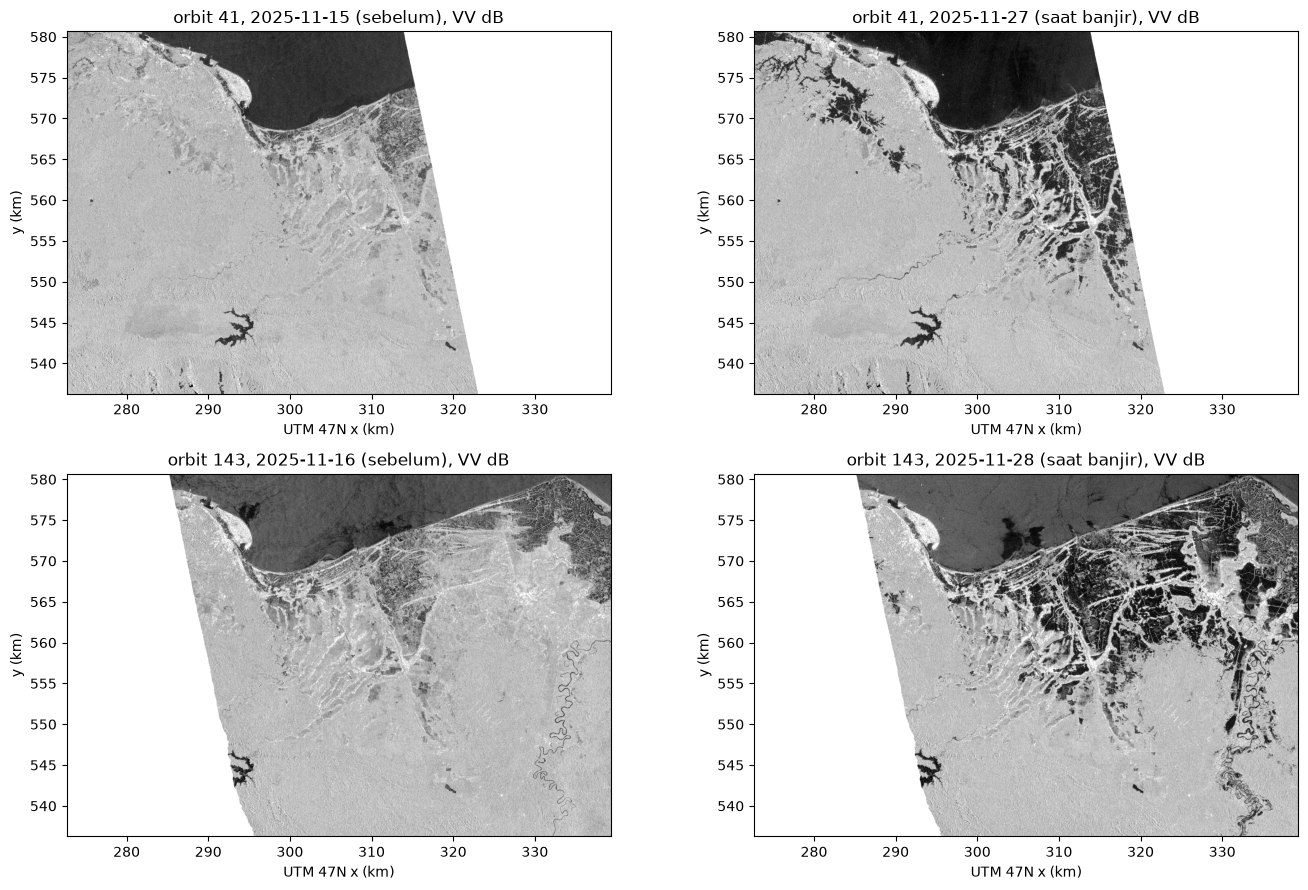

In [5]:
def valid_mask(lin):
    return np.isfinite(lin) & (lin > 0)


def to_db(lin):
    out = np.full(lin.shape, np.nan, dtype="float32")
    ok = valid_mask(lin)
    out[ok] = 10 * np.log10(lin[ok])
    return out


for k, v in s1.items():
    v["valid"] = valid_mask(v["vv"]) & valid_mask(v["vh"])
    print(k, f"valid {v['valid'].mean():.0%}", f"| VV median {np.nanmedian(to_db(v['vv'])):.1f} dB")

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for r, orbit in enumerate(PASANGAN):
    for c, label in enumerate(("pre", "evt")):
        a = ax[r, c]
        a.imshow(to_db(s1[orbit, label]["vv"]), cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
        a.set_title(f"orbit {orbit}, {PASANGAN[orbit][c]} ({'sebelum' if label == 'pre' else 'saat banjir'}), VV dB")
        a.set_xlabel("UTM 47N x (km)")
        a.set_ylabel("y (km)")
plt.tight_layout()
plt.savefig(GAMBAR / "01-vv-sebelum-saat-banjir.png", dpi=110, bbox_inches="tight")
plt.show()

## 3. Mask Pendukung: Air Permanen dan Lereng

Dua sumber false positive yang sudah bisa dibuang sebelum thresholding:

1. laut dan badan air permanen, dari kelas 80 ESA WorldCover. backscatter laut bisa berubah antar tanggal karena angin, jadi tanpa mask ini laut sering ikut terdeteksi sebagai "genangan baru"
2. lereng di atas 5°. di daerah berbukit ada radar shadow yang gelap mirip air. lereng dihitung dari Copernicus DEM dengan gradien numerik

Copernicus DEM sebenarnya DSM, tinggi permukaannya ikut tinggi kanopi. kalau lereng langsung dihitung di grid 20 m, tepi kebun dan hutan ikut terbaca sebagai lereng curam (median lereng di area valid 5,7°, padahal sebagian besar dataran rendah). DEM dihaluskan dulu dengan rata rata 9x9 (180 m) supaya lereng lebih mewakili bentuk medan, median turun ke 3,1°

In [6]:
dem_halus = cv2.blur(dem, (9, 9))
gy, gx = np.gradient(dem_halus, RES)
lereng = np.degrees(np.arctan(np.hypot(gx, gy)))
air_permanen = wc == 80
mask_lereng = lereng > 5
print(f"air permanen {air_permanen.mean():.1%} | lereng > 5° {mask_lereng.mean():.1%} dari kotak studi")

air permanen 15.5% | lereng > 5° 24.0% dari kotak studi


## 4. Perbandingan Filter Speckle

Speckle adalah noise multiplikatif bawaan citra SAR, bentuknya bintik terang gelap acak bahkan di permukaan yang seragam. Lima perlakuan dibandingkan pada citra VV saat banjir orbit 41:

| filter | domain | ukuran kernel |
| --- | --- | --- |
| tanpa filter | - | - |
| mean | linear | 5x5 |
| gaussian | linear | 5x5, σ = 1,5 |
| median | dB | 5x5 |
| Lee | linear | 5x5 dan 7x7 |

Dua ukuran yang dipakai:

- ENL (equivalent number of looks) = mean² / varians pada area homogen, makin tinggi makin halus. area homogen dipilih otomatis dari jendela 31x31 dengan koefisien variasi terkecil di daratan datar
- η Otsu = varians antar kelas / varians total. Otsu memilih ambang yang memaksimalkan varians antar kelas, jadi η dekat 1 berarti histogram terpisah jelas menjadi dua kelompok (air dan bukan air)

Filter Lee memakai bobot `W = 1 - Cu²/Ci²` (dipotong ke 0..1), dengan `Ci` koefisien variasi lokal dan `Cu² = 1/ENL` dari citra tanpa filter. di area homogen `W` mendekati 0 jadi piksel diganti rata rata lokal, di tepi atau objek `W` mendekati 1 jadi nilai asli dipertahankan

In [7]:
def isi_nan(img):
    """cv2 tidak bisa memproses NaN, jadi no-data diisi median sementara"""
    out = img.astype("float32").copy()
    out[~np.isfinite(out)] = np.nanmedian(out)
    return out


def lee(lin, size, enl):
    m = cv2.blur(lin, (size, size))
    m2 = cv2.blur(lin * lin, (size, size))
    var = np.maximum(m2 - m * m, 0)
    ci2 = var / np.maximum(m * m, 1e-12)
    w = np.clip(1 - (1 / enl) / np.maximum(ci2, 1e-12), 0, 1)
    return m + w * (lin - m)


def filter_speckle(lin, nama, enl):
    x = isi_nan(np.where(valid_mask(lin), lin, np.nan))
    if nama == "tanpa filter":
        out = x
    elif nama == "mean 5x5":
        out = cv2.blur(x, (5, 5))
    elif nama == "gaussian 5x5":
        out = cv2.GaussianBlur(x, (5, 5), 1.5)
    elif nama == "median 5x5":  # median di domain dB, hasil dikembalikan ke linear
        out = 10 ** (cv2.medianBlur(10 * np.log10(np.maximum(x, 1e-6)), 5) / 10)
    elif nama.startswith("lee"):
        out = lee(x, int(nama.split()[1][0]), enl)
    out = out.astype("float32")
    out[~valid_mask(lin)] = np.nan
    return out


def cari_patch_homogen(lin, darat, size=31):
    x = isi_nan(np.where(valid_mask(lin), lin, np.nan))
    m = cv2.blur(x, (size, size))
    v = np.maximum(cv2.blur(x * x, (size, size)) - m * m, 0)
    cv_map = v / np.maximum(m * m, 1e-12)
    ok = cv2.erode(darat.astype("uint8"), np.ones((size, size), np.uint8)).astype(bool)
    h = size // 2
    # erode menganggap luar citra sebagai daratan, jadi pinggiran citra dikeluarkan manual
    ok[:h], ok[-h:], ok[:, :h], ok[:, -h:] = False, False, False, False
    cv_map[~ok] = np.inf
    r, c = np.unravel_index(np.argmin(cv_map), cv_map.shape)
    return np.s_[r - h:r + h + 1, c - h:c + h + 1]


def enl(lin, patch):
    p = lin[patch]
    return float(np.nanmean(p) ** 2 / np.nanvar(p))


def otsu_eta(db, mask):
    x = db[mask & np.isfinite(db)]
    t = threshold_otsu(x)
    a, b = x[x < t], x[x >= t]
    w0 = a.size / x.size
    sb = w0 * (1 - w0) * (a.mean() - b.mean()) ** 2
    return float(t), float(sb / x.var())


evt41 = s1[41, "evt"]
darat_datar = evt41["valid"] & ~air_permanen & ~mask_lereng
patch = cari_patch_homogen(evt41["vv"], darat_datar)
ENL_RAW = enl(evt41["vv"], patch)
print(f"ENL citra tanpa filter di patch homogen: {ENL_RAW:.2f}")

FILTER = ["tanpa filter", "mean 5x5", "gaussian 5x5", "median 5x5", "lee 5x5", "lee 7x7"]
hasil_filter = {}
print(f"{'filter':<14}{'ENL':>8}{'ambang Otsu (dB)':>18}{'η Otsu':>9}")
for f in FILTER:
    lin = filter_speckle(evt41["vv"], f, ENL_RAW)
    db = to_db(lin)
    t, eta = otsu_eta(db, evt41["valid"] & ~air_permanen)
    hasil_filter[f] = db
    print(f"{f:<14}{enl(lin, patch):>8.2f}{t:>18.2f}{eta:>9.3f}")

ENL citra tanpa filter di patch homogen: 19.65
filter             ENL  ambang Otsu (dB)   η Otsu


tanpa filter     19.65            -12.42    0.734


mean 5x5        125.31            -11.78    0.771


gaussian 5x5    100.73            -11.79    0.771


median 5x5      107.98            -12.32    0.830


lee 5x5          99.23            -12.33    0.773


lee 7x7         155.42            -12.23    0.775


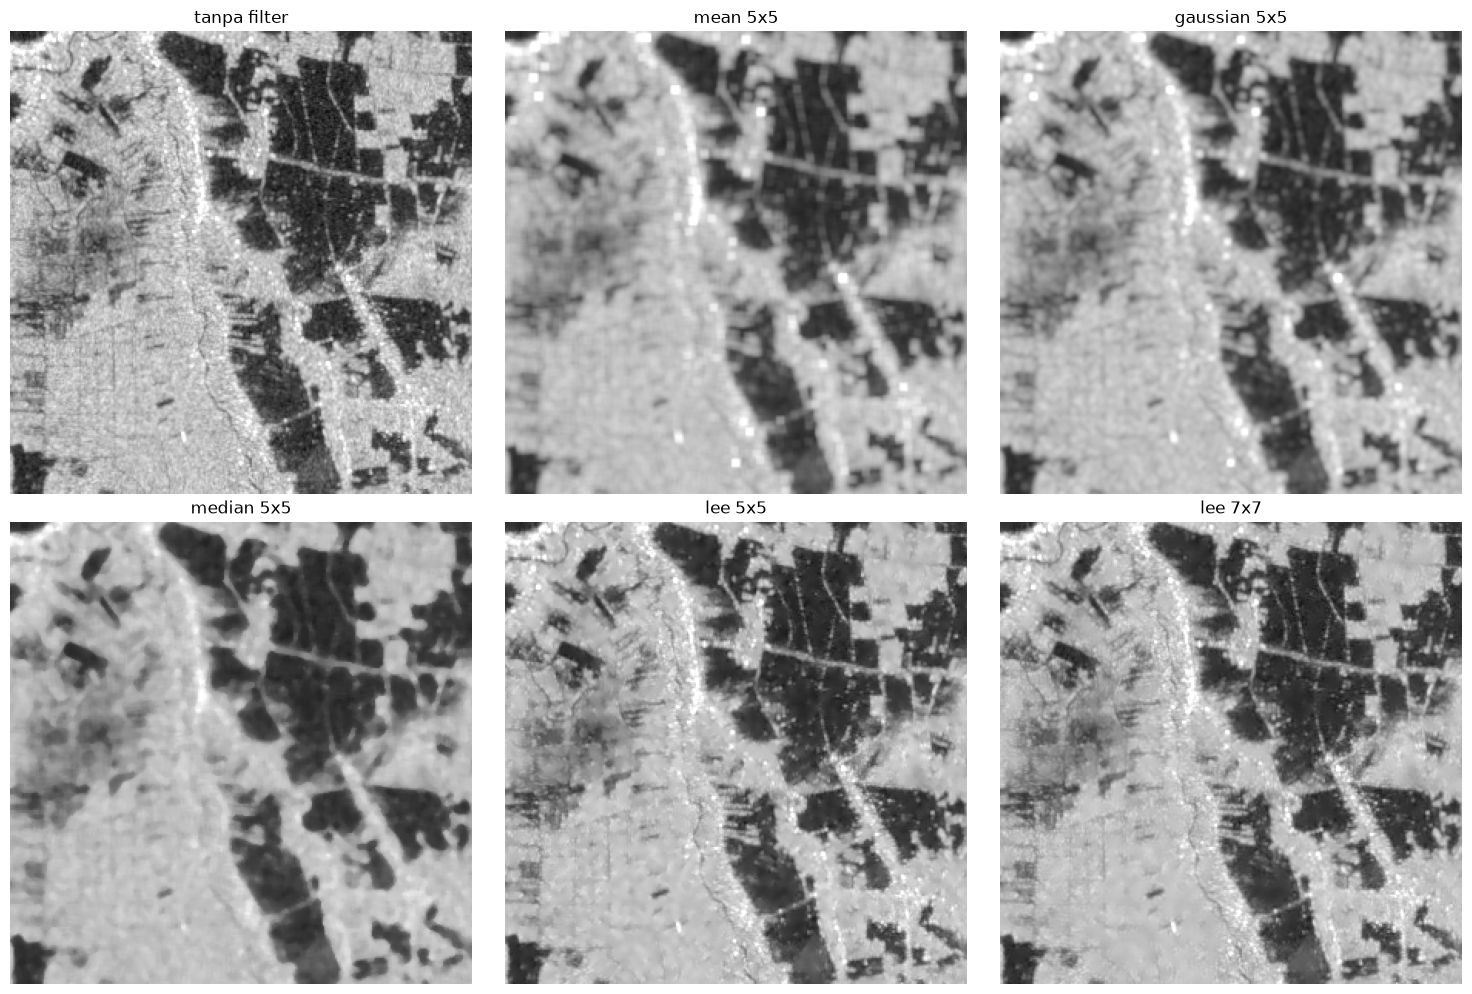

In [8]:
# Potongan 6 x 6 km yang separuhnya air, dipilih otomatis supaya tepi genangan ikut terlihat
air_raw = (hasil_filter["tanpa filter"] < otsu_eta(hasil_filter["tanpa filter"], evt41["valid"])[0]).astype("float32")
frac = cv2.blur(air_raw, (301, 301))
ok = cv2.erode(darat_datar.astype("uint8"), np.ones((301, 301), np.uint8)).astype(bool)
r, c = np.unravel_index(np.argmin(np.where(ok, np.abs(frac - 0.5), np.inf)), frac.shape)
crop = np.s_[r - 150:r + 150, c - 150:c + 150]
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for a, f in zip(ax.ravel(), FILTER):
    a.imshow(hasil_filter[f][crop], cmap="gray", vmin=-25, vmax=0)
    a.set_title(f)
    a.axis("off")
plt.tight_layout()
plt.savefig(GAMBAR / "02-perbandingan-filter-speckle.png", dpi=110, bbox_inches="tight")
plt.show()

Semua filter menaikkan ENL dari 19,65 dan η dari 0,734. Median 5x5 punya η tertinggi (0,830), tapi di potongan citra terlihat jalan dan pematang yang lebarnya satu dua piksel ikut hilang, petak sawah yang tergenang jadi menyatu. mean dan gaussian menyisakan blok blok terang di sekitar objek kuat seperti bangunan. Lee 7x7 punya ENL tertinggi (155,42) dan tetap menyisakan garis jalan dan pematang, dengan η 0,775 yang hanya sedikit di bawah median

Yang dipakai untuk tahap berikutnya Lee 7x7, karena peta genangan nanti dipotong per petak lahan dan tepi petak yang hilang membuat luas genangan melebar. pilihan ini bisa diganti di variabel `FILTER_DIPAKAI`

In [9]:
FILTER_DIPAKAI = "lee 7x7"
db = {}
for k, v in s1.items():
    for pol in ("vv", "vh"):
        db[k + (pol,)] = to_db(filter_speckle(v[pol], FILTER_DIPAKAI, ENL_RAW))

## 5. Histogram dan Thresholding Otsu

Otsu dihitung terpisah untuk tiap citra, hanya dari piksel valid di luar air permanen. dengan begitu ambang tidak didominasi puncak laut, dan tiap tanggal mendapat ambang sesuai kondisi citranya sendiri

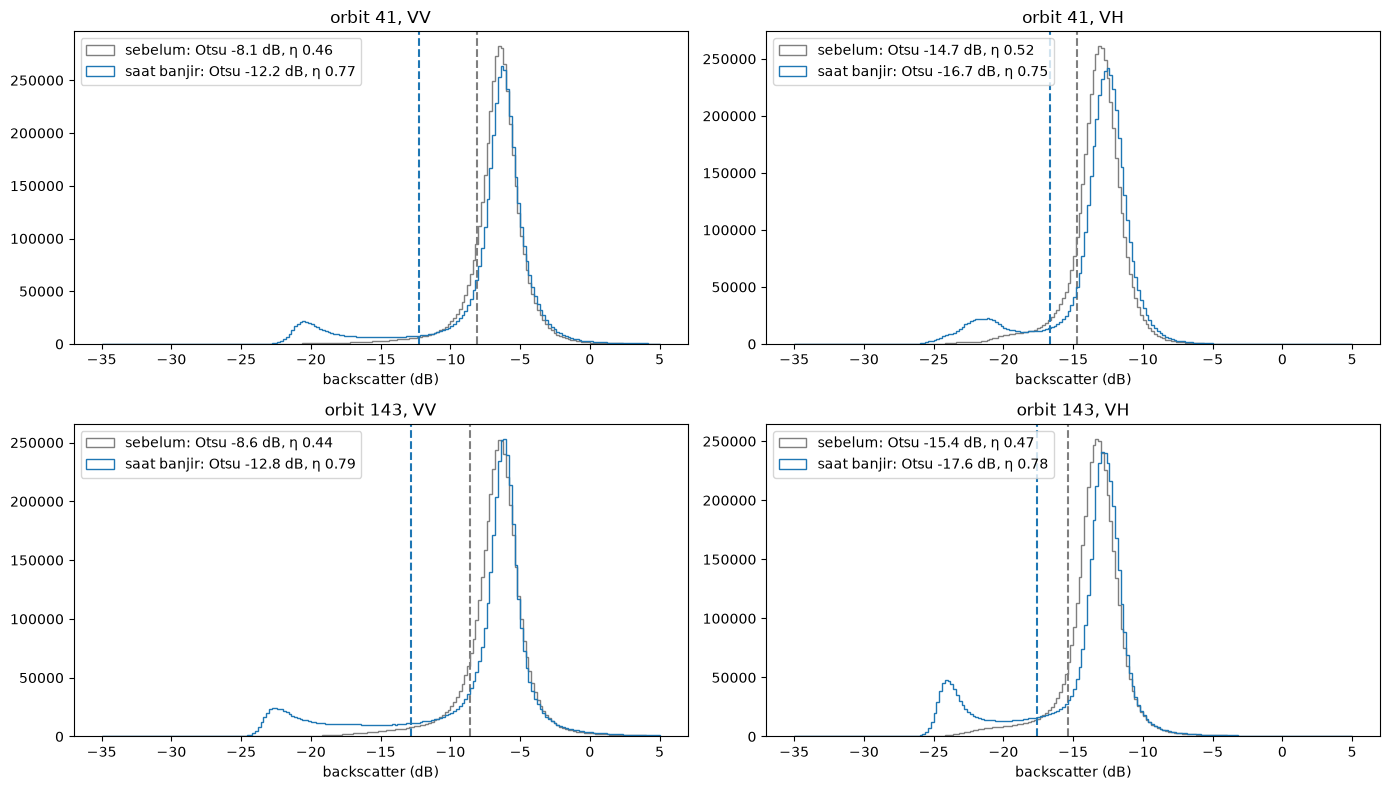

(41, 'pre', 'vv') -8.12 dB
(41, 'evt', 'vv') -12.23 dB
(41, 'pre', 'vh') -14.71 dB
(41, 'evt', 'vh') -16.67 dB
(143, 'pre', 'vv') -8.60 dB
(143, 'evt', 'vv') -12.83 dB
(143, 'pre', 'vh') -15.37 dB
(143, 'evt', 'vh') -17.56 dB


In [10]:
ambang = {}
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for r, orbit in enumerate(PASANGAN):
    for c, pol in enumerate(("vv", "vh")):
        a = ax[r, c]
        for label, warna in (("pre", "tab:gray"), ("evt", "tab:blue")):
            m = s1[orbit, label]["valid"] & ~air_permanen
            t, eta = otsu_eta(db[orbit, label, pol], m)
            ambang[orbit, label, pol] = t
            a.hist(db[orbit, label, pol][m], bins=200, range=(-35, 5), histtype="step", color=warna,
                   label=f"{'sebelum' if label == 'pre' else 'saat banjir'}: Otsu {t:.1f} dB, η {eta:.2f}")
            a.axvline(t, color=warna, ls="--")
        a.set_title(f"orbit {orbit}, {pol.upper()}")
        a.set_xlabel("backscatter (dB)")
        a.legend()
plt.tight_layout()
plt.savefig(GAMBAR / "03-histogram-otsu.png", dpi=110, bbox_inches="tight")
plt.show()
for k, t in ambang.items():
    print(k, f"{t:.2f} dB")

Histogram citra saat banjir punya dua puncak yang jelas, air di sekitar -21 sampai -23 dB (VV) dan daratan di sekitar -6 dB, dan Otsu jatuh di lembah di antaranya (-12,2 dB orbit 41, -12,8 dB orbit 143, η 0,77 sampai 0,79)

Histogram citra sebelum banjir hanya punya satu puncak, karena di luar air permanen hampir tidak ada air. Otsu tetap mengembalikan satu ambang, tapi jatuhnya di -8,1 dan -8,6 dB, di lereng kiri puncak daratan, dengan η hanya 0,44 sampai 0,52. ambang itu membelah daratan menjadi dua kelompok, bukan memisahkan air. kalau dipakai, sebagian besar daratan basah akan dianggap "sudah air sebelumnya" dan genangan baru jadi terlalu kecil. karena itu di tahap berikutnya citra sebelum banjir memakai ambang Otsu citra saat banjir dari orbit yang sama. geometri pengamatannya sama, jadi ambang air seharusnya juga sama

## 6. Change Detection dan Penggabungan Mask

Air saat banjir belum tentu genangan, karena sungai, tambak, dan sawah yang memang sedang digenangi juga gelap di tanggal sebelumnya. Genangan baru didefinisikan sebagai piksel yang memenuhi semuanya:

1. VV saat banjir di bawah ambang Otsu citra saat banjir
2. VV sebelum banjir di atas ambang yang sama (bukan air sebelumnya)
3. selisih VV (saat - sebelum) di bawah -3 dB, artinya backscatter turun minimal ke setengahnya (10·log10(0,5) ≈ -3 dB)
4. bukan air permanen, bukan lereng > 5°, dan valid di kedua tanggal

Sesudah itu dua operasi morfologi: opening 3x3 untuk membuang piksel lepas sisa speckle, lalu connected component dengan 8-ketetanggaan, komponen di bawah 10 piksel (0,4 ha) dibuang sebagai minimum mapping unit

In [11]:
SELISIH_MIN = -3.0
MMU_PX = 10


def bersihkan(mask, mmu=MMU_PX):
    m = cv2.morphologyEx(mask.astype("uint8"), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= mmu
    return keep[lab]


genangan, tahap = {}, {}
for orbit in PASANGAN:
    pre, evt = db[orbit, "pre", "vv"], db[orbit, "evt", "vv"]
    valid = s1[orbit, "pre"]["valid"] & s1[orbit, "evt"]["valid"]
    t_air = ambang[orbit, "evt", "vv"]  # ambang citra sebelum banjir tidak dipakai, lihat pembahasan histogram
    air_evt = evt < t_air
    air_pre = pre < t_air
    selisih = evt - pre
    kandidat = valid & air_evt & ~air_pre & (selisih < SELISIH_MIN)
    kandidat_mask = kandidat & ~air_permanen & ~mask_lereng
    akhir = bersihkan(kandidat_mask)
    genangan[orbit] = akhir
    tahap[orbit] = dict(selisih=selisih, air_evt=air_evt & valid, kandidat=kandidat,
                        kandidat_mask=kandidat_mask, akhir=akhir, valid=valid, air_pre=air_pre & valid)
    print(f"orbit {orbit}: air saat banjir {(air_evt & valid).sum() * PX_HA:,.0f} ha"
          f" | kandidat {kandidat.sum() * PX_HA:,.0f} ha"
          f" | sesudah mask {kandidat_mask.sum() * PX_HA:,.0f} ha"
          f" | sesudah morfologi {akhir.sum() * PX_HA:,.0f} ha")

orbit 41: air saat banjir 46,951 ha | kandidat 16,130 ha | sesudah mask 15,170 ha | sesudah morfologi 13,001 ha


orbit 143: air saat banjir 71,633 ha | kandidat 25,962 ha | sesudah mask 23,971 ha | sesudah morfologi 20,980 ha


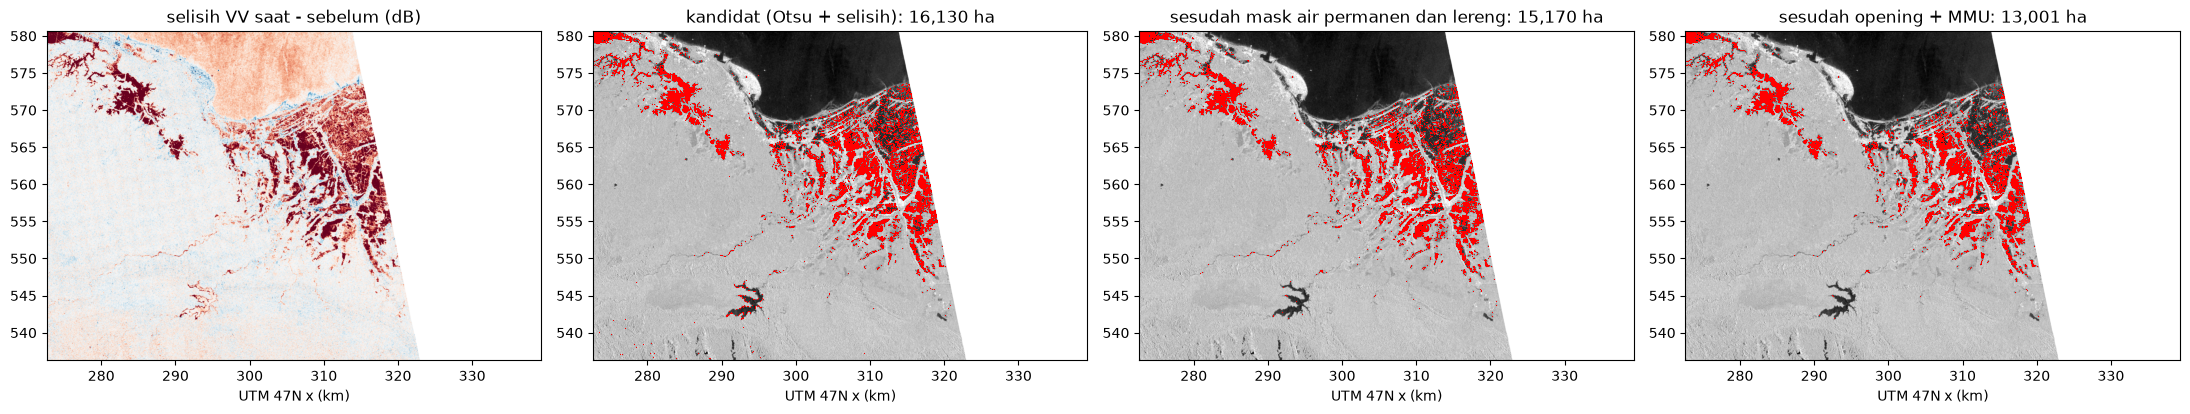

In [12]:
t = tahap[41]
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
ax[0].imshow(t["selisih"], cmap="RdBu", vmin=-10, vmax=10, extent=EXTENT)
ax[0].set_title("selisih VV saat - sebelum (dB)")
for a, k, judul in zip(ax[1:], ("kandidat", "kandidat_mask", "akhir"),
                       ("kandidat (Otsu + selisih)", "sesudah mask air permanen dan lereng", "sesudah opening + MMU")):
    a.imshow(db[41, "evt", "vv"], cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
    a.imshow(np.ma.masked_equal(t[k].astype("uint8"), 0), cmap=ListedColormap(["red"]), extent=EXTENT, interpolation="nearest")
    a.set_title(f"{judul}: {t[k].sum() * PX_HA:,.0f} ha")
for a in ax:
    a.set_xlabel("UTM 47N x (km)")
plt.tight_layout()
plt.savefig(GAMBAR / "04-change-detection-dan-mask.png", dpi=110, bbox_inches="tight")
plt.show()

Di orbit 41, air saat banjir 46.951 ha tapi yang lolos sebagai kandidat genangan baru hanya 16.130 ha, sisanya air yang sudah ada sebelumnya (laut, sungai, tambak) atau penurunan backscatter yang kurang dari 3 dB. mask air permanen dan lereng memangkas 960 ha lagi, lalu opening dan MMU membuang 2.169 ha piksel lepas, jadi tersisa 13.001 ha. polanya sama di orbit 143: 25.962 ha kandidat, 23.971 ha sesudah mask, 20.980 ha sesudah morfologi

## 7. Penggabungan Dua Orbit

Orbit 41 (27 November) menutup bagian barat kotak studi dan orbit 143 (28 November) menutup bagian timur, dengan irisan di tengah. Peta gabungan memakai orbit 41 di piksel yang valid untuk orbit 41, sisanya diisi orbit 143. di irisan kedua orbit dibandingkan, walau selisih satu hari berarti perbedaannya bisa juga karena genangan bertambah atau surut

In [13]:
v41, v143 = tahap[41]["valid"], tahap[143]["valid"]
gabung = np.where(v41, genangan[41], genangan[143])
cakupan = v41 | v143
irisan = v41 & v143 & ~air_permanen & ~mask_lereng
a, b = genangan[41][irisan], genangan[143][irisan]
print(f"cakupan gabungan {cakupan.mean():.0%} kotak studi | irisan {irisan.sum() * PX_HA:,.0f} ha")
print(f"di irisan: genangan 27 Nov {a.sum() * PX_HA:,.0f} ha, 28 Nov {b.sum() * PX_HA:,.0f} ha,"
      f" kesesuaian piksel {np.mean(a == b):.1%}, IoU {np.sum(a & b) / max(np.sum(a | b), 1):.2f}")
print(f"luas genangan gabungan: {gabung.sum() * PX_HA:,.0f} ha")

cakupan gabungan 100% kotak studi | irisan 73,576 ha
di irisan: genangan 27 Nov 10,156 ha, 28 Nov 6,697 ha, kesesuaian piksel 92.6%, IoU 0.51
luas genangan gabungan: 27,285 ha


Dua orbit menutup seluruh kotak studi. di irisan seluas 73.576 ha, genangan 27 November 10.156 ha dan 28 November 6.697 ha, dengan kesesuaian piksel 92,6% dan IoU 0,51. kesesuaian piksel tinggi karena sebagian besar irisan memang bukan genangan di kedua tanggal, IoU yang hanya menghitung piksel genangan lebih jujur menggambarkan selisihnya. selisih ini bisa dari genangan yang mulai surut dalam sehari, bisa juga dari sudut datang yang beda, karena irisan berada di far range orbit 41 dan near range orbit 143. dua penyebab ini belum bisa dipisahkan dengan data yang ada

## 8. Validasi dengan Sentinel-2 (29 November 2025)

Sentinel-2 optik tidak tembus awan, jadi validasi hanya di piksel cerah menurut Scene Classification Layer (SCL kelas 4 vegetasi, 5 tanah terbuka, 6 air, 7 tidak terklasifikasi). Air di Sentinel-2 dideteksi dengan MNDWI = (hijau - SWIR1) / (hijau + SWIR1) dan ambang Otsu

Yang dibandingkan adalah peta air total (air saat banjir dari Sentinel-1, di luar air permanen), bukan peta genangan baru, karena Sentinel-2 hanya punya satu tanggal di sini. Dua hal yang membuat angka ini bukan akurasi murni: jeda satu sampai dua hari antara citra, dan MNDWI tidak melihat air di bawah kanopi atau tanaman padi yang rapat

In [14]:
s2 = muat("s2_" + S2_TANGGAL, "sentinel-2-l2a", ["B02", "B03", "B04", "B08", "B11", "SCL"], S2_TANGGAL,
          resampling={"SCL": "nearest", "*": "bilinear"})
offset = 1000 if float(s2["baseline"]) >= 4 else 0  # baseline 04.00 ke atas punya offset +1000
refl = {b: (s2[b].astype("float32") - offset) / 10000 for b in ("B02", "B03", "B04", "B08", "B11")}
mndwi = (refl["B03"] - refl["B11"]) / np.maximum(refl["B03"] + refl["B11"], 1e-6)
cerah = np.isin(s2["SCL"], [4, 5, 6, 7]) & np.isfinite(mndwi)
t_mndwi = threshold_otsu(mndwi[cerah & ~air_permanen])
air_s2 = mndwi > t_mndwi
print(f"processing baseline {float(s2['baseline']):.2f} | piksel cerah {cerah.mean():.1%} | ambang MNDWI Otsu {t_mndwi:.3f}")

air_s1 = np.where(v41, tahap[41]["air_evt"], tahap[143]["air_evt"])
uji = cerah & cakupan & ~air_permanen & ~mask_lereng
y_ref, y_pred = air_s2[uji], air_s1[uji]
tp = np.sum(y_ref & y_pred)
tn = np.sum(~y_ref & ~y_pred)
fp = np.sum(~y_ref & y_pred)
fn = np.sum(y_ref & ~y_pred)
n = tp + tn + fp + fn
oa = (tp + tn) / n
pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / n**2
kappa = (oa - pe) / (1 - pe)
presisi, recall = tp / (tp + fp), tp / (tp + fn)
f1 = 2 * presisi * recall / (presisi + recall)
print(f"piksel uji {n:,} ({n * PX_HA:,.0f} ha)")
print(f"confusion matrix (baris = Sentinel-2, kolom = Sentinel-1):\n  air    : {tp:>9,} {fn:>9,}\n  bukan  : {fp:>9,} {tn:>9,}")
print(f"OA {oa:.3f} | kappa {kappa:.3f} | presisi {presisi:.3f} | recall {recall:.3f} | F1 {f1:.3f}")

print("\nair yang hanya terdeteksi Sentinel-2, per kelas WorldCover:")
hanya_s2 = uji & air_s2 & ~air_s1
for k, nama in KELAS.items():
    m = hanya_s2 & (wc == k)
    if m.any():
        print(f"  {nama:<16}{m.sum() * PX_HA:>9,.0f} ha  ({m.sum() / hanya_s2.sum():.1%})")

processing baseline 5.11 | piksel cerah 81.2% | ambang MNDWI Otsu 0.122
piksel uji 3,638,078 (145,523 ha)
confusion matrix (baris = Sentinel-2, kolom = Sentinel-1):
  air    :   767,713   334,200
  bukan  :    80,337 2,455,828
OA 0.886 | kappa 0.711 | presisi 0.905 | recall 0.697 | F1 0.787

air yang hanya terdeteksi Sentinel-2, per kelas WorldCover:
  pohon               6,247 ha  (46.7%)
  semak                  11 ha  (0.1%)
  rumput              1,240 ha  (9.3%)
  lahan pertanian     4,802 ha  (35.9%)
  terbangun             271 ha  (2.0%)
  lahan terbuka         213 ha  (1.6%)
  lahan basah           479 ha  (3.6%)
  mangrove              104 ha  (0.8%)


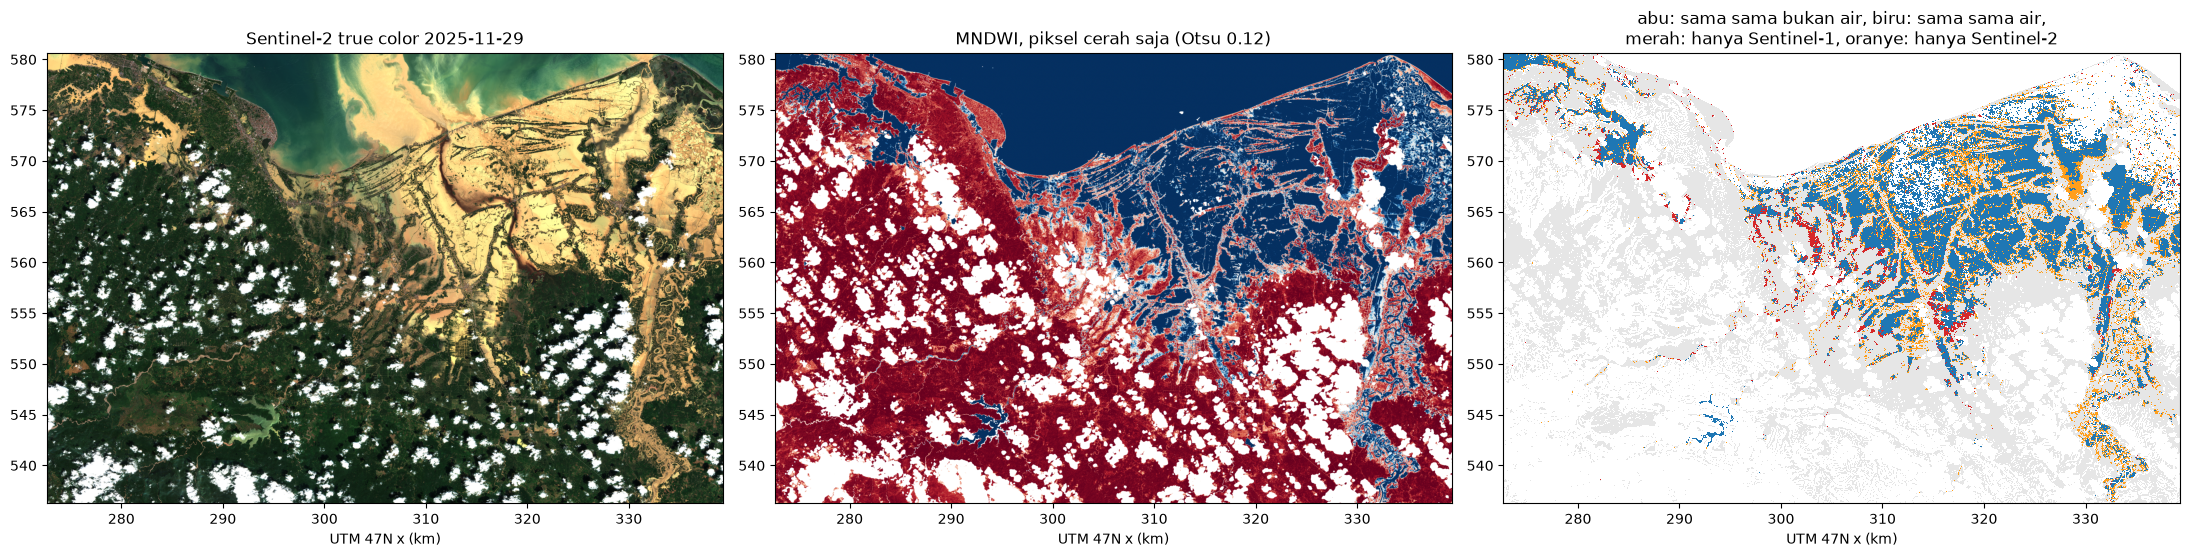

In [15]:
rgb = np.dstack([refl["B04"], refl["B03"], refl["B02"]])
rgb = np.clip(rgb / 0.25, 0, 1)
fig, ax = plt.subplots(1, 3, figsize=(22, 6))
ax[0].imshow(rgb, extent=EXTENT)
ax[0].set_title(f"Sentinel-2 true color {S2_TANGGAL}")
ax[1].imshow(np.where(cerah, mndwi, np.nan), cmap="RdBu", vmin=-0.6, vmax=0.6, extent=EXTENT)
ax[1].set_title(f"MNDWI, piksel cerah saja (Otsu {t_mndwi:.2f})")
banding = np.full(uji.shape, np.nan)
banding[uji] = 0
banding[uji & air_s1 & air_s2] = 1
banding[uji & air_s1 & ~air_s2] = 2
banding[uji & ~air_s1 & air_s2] = 3
ax[2].imshow(banding, cmap=ListedColormap(["#e6e6e6", "#1f77b4", "#d62728", "#ff9f1c"]), vmin=-0.5, vmax=3.5,
             extent=EXTENT, interpolation="nearest")
ax[2].set_title("abu: sama sama bukan air, biru: sama sama air,\nmerah: hanya Sentinel-1, oranye: hanya Sentinel-2")
for a in ax:
    a.set_xlabel("UTM 47N x (km)")
plt.tight_layout()
plt.savefig(GAMBAR / "05-validasi-sentinel2.png", dpi=110, bbox_inches="tight")
plt.show()

Citra Sentinel-2 29 November ternyata 81,2% cerah di kotak studi, jadi validasi mencakup 145.523 ha. hasilnya OA 0,886, kappa 0,711, presisi 0,905, dan recall 0,697

Presisi tinggi berarti piksel yang disebut air oleh Sentinel-1 hampir selalu juga air di Sentinel-2. recall yang lebih rendah berarti sekitar 30% air yang terlihat di Sentinel-2 terlewat oleh Sentinel-1. dari 13.367 ha air yang hanya terdeteksi Sentinel-2, 46,7% berada di kelas pohon dan 35,9% di lahan pertanian. ini sesuai dengan keterbatasan radar di genangan bervegetasi: batang dan tanaman yang berdiri di atas air memantulkan sinyal balik ke sensor (double bounce), jadi permukaannya terang, bukan gelap. kemungkinan lain genangan bertambah antara 27-28 dan 29 November, dan kelas WorldCover 2021 yang sudah tidak sesuai kondisi 2025

## 9. Peta Genangan dan Luas per Tutupan Lahan

Luas genangan baru dipecah menurut kelas ESA WorldCover 2021. ini analisis awal untuk melihat jenis lahan yang paling banyak tergenang. kotak studi masih berupa bounding box, belum dipotong batas administrasi Aceh Utara dan Lhokseumawe

kelas            luas kelas (ha)  tergenang (ha)  persen
pohon                    188,712           1,737    0.9%
semak                         60               8   13.6%
rumput                     9,741           1,571   16.1%
lahan pertanian           42,281          23,162   54.8%


terbangun                  5,010              16    0.3%
lahan terbuka              1,504             288   19.1%
air permanen              45,874               0    0.0%
lahan basah                2,417             495   20.5%
mangrove                     726               8    1.1%
total                    296,326          27,285


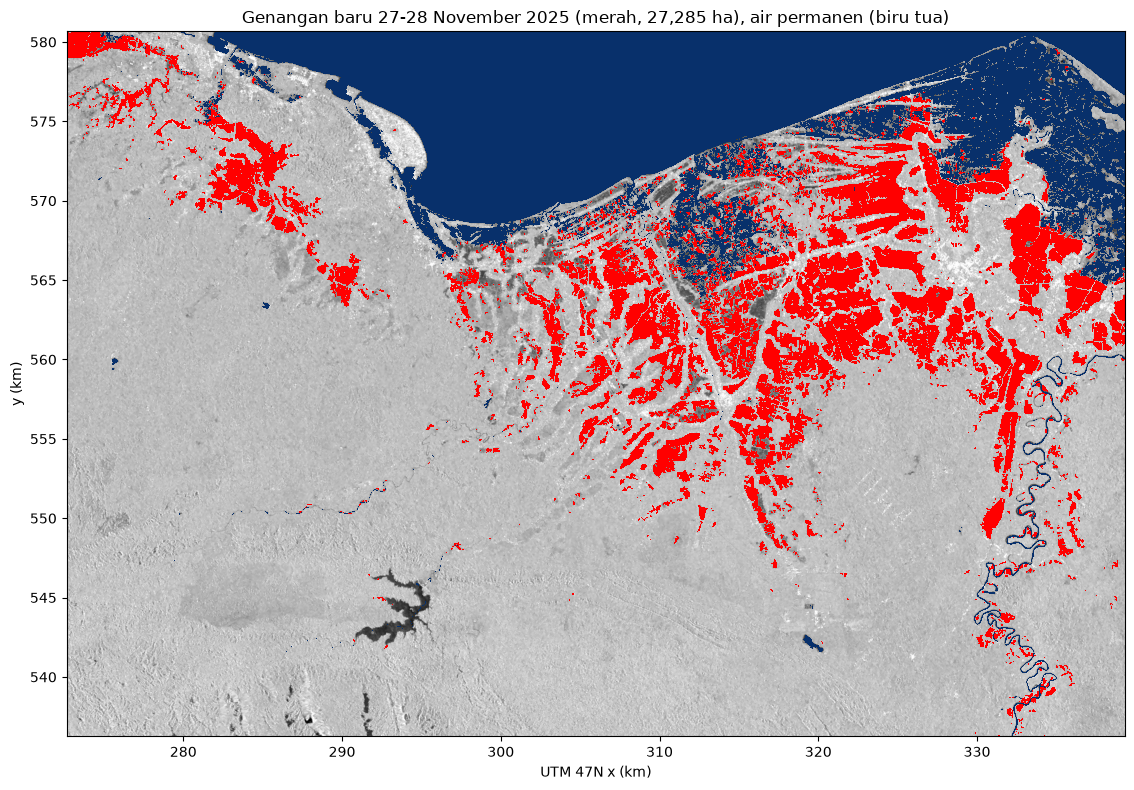

In [16]:
print(f"{'kelas':<16}{'luas kelas (ha)':>16}{'tergenang (ha)':>16}{'persen':>8}")
for k, nama in KELAS.items():
    m = (wc == k) & cakupan
    if m.sum() == 0:
        continue
    g = (gabung & m).sum()
    print(f"{nama:<16}{m.sum() * PX_HA:>16,.0f}{g * PX_HA:>16,.0f}{g / m.sum():>8.1%}")
print(f"{'total':<16}{cakupan.sum() * PX_HA:>16,.0f}{gabung.sum() * PX_HA:>16,.0f}")

fig, a = plt.subplots(figsize=(12, 8))
dasar = np.where(v41, db[41, "pre", "vv"], db[143, "pre", "vv"])
a.imshow(dasar, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
a.imshow(np.ma.masked_equal(air_permanen.astype("uint8"), 0), cmap=ListedColormap(["#08306b"]), extent=EXTENT,
         interpolation="nearest")
a.imshow(np.ma.masked_equal(gabung.astype("uint8"), 0), cmap=ListedColormap(["red"]), extent=EXTENT,
         interpolation="nearest")
a.set_title(f"Genangan baru 27-28 November 2025 (merah, {gabung.sum() * PX_HA:,.0f} ha), air permanen (biru tua)")
a.set_xlabel("UTM 47N x (km)")
a.set_ylabel("y (km)")
plt.tight_layout()
plt.savefig(GAMBAR / "06-peta-genangan.png", dpi=110, bbox_inches="tight")
plt.show()

Genangan baru gabungan 27.285 ha, dan 23.162 ha di antaranya (85%) berada di lahan pertanian, setara 54,8% dari seluruh lahan pertanian di kotak studi. kelas terbangun hanya 16 ha tergenang (0,3%), padahal citra Sentinel-2 29 November memperlihatkan Lhoksukon dikelilingi air. angka ini lebih mungkin menunjukkan batas metode (double bounce di permukiman) dibanding kondisi lapangan, jadi luas genangan permukiman belum bisa dilaporkan dari tahap ini

Mulyani dkk. (2026) mendapat sekitar 102.189 ha sawah terdampak, tapi wilayahnya mencakup Aceh bagian timur dan Sumatera Utara, jadi belum bisa dibandingkan langsung dengan kotak studi ini

Yang belum dikerjakan di notebook ini: memotong peta dengan batas administrasi kecamatan, durasi genangan dari scene Desember, dan pengecekan ambang -3 dB serta MMU 10 piksel dengan beberapa nilai lain